In [15]:
# ==========================================
# CAMPUS MAINTENANCE ML PROJECT
# STEP 1: IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

All libraries imported successfully!
Pandas version: 2.3.3
NumPy version: 2.1.3


In [33]:
# ==========================================
# V4 DATASET LOADING
# ==========================================

df_v4 = pd.read_csv(
    "dataset/campus_maintenance_website_aligned_synthetic_v4_300.csv"
)

print("V4 Dataset Loaded Successfully!")
print("Dataset Shape:", df_v4.shape)

print("Unique Scenarios:", df_v4["scenario_id"].nunique())
print("Unique Titles:", df_v4["title"].nunique())
print("Unique Descriptions:", df_v4["description"].nunique())

print("\nCategory Distribution:")
display(df_v4["category"].value_counts())

print("\nPriority Distribution:")
display(df_v4["priority"].value_counts())

V4 Dataset Loaded Successfully!
Dataset Shape: (300, 19)
Unique Scenarios: 300
Unique Titles: 300
Unique Descriptions: 300

Category Distribution:


category
Electrical           50
Plumbing             50
Cleaning             50
Damaged Furniture    50
IT/Network           50
Other                50
Name: count, dtype: int64


Priority Distribution:


priority
Medium    120
High      100
Low        80
Name: count, dtype: int64

In [34]:
# ==========================================
# V4 DATA QUALITY CHECK
# ==========================================

print("MISSING VALUES:")
display(df_v4.isnull().sum().to_frame("Missing Values"))

print("\nDUPLICATE ROWS:")
print(df_v4.duplicated().sum())

print("\nDUPLICATE SCENARIO IDs:")
print(df_v4["scenario_id"].duplicated().sum())

print("\nPRIORITY CONFLICTS:")
conflicts = (
    df_v4.groupby("scenario_id")["priority"].nunique() > 1
).sum()

print(conflicts)

print("\nCATEGORY CONFLICTS:")
category_conflicts = (
    df_v4.groupby("scenario_id")["category"].nunique() > 1
).sum()

print(category_conflicts)


MISSING VALUES:


,Missing Values
scenario_id,0
complaint_id,0
student_id,0
date_submitted,0
submitted_hour,0
category,0
location,0
title,0
description,0
has_media,0



DUPLICATE ROWS:
0

DUPLICATE SCENARIO IDs:
0

PRIORITY CONFLICTS:
0

CATEGORY CONFLICTS:
0


In [35]:
print("DATASET INFORMATION")
print("-" * 50)

df_v4.info()

print("\nNUMERICAL SUMMARY")
display(df_v4.describe())

print("\nCATEGORY DISTRIBUTION")
display(df_v4["category"].value_counts())

print("\nPRIORITY DISTRIBUTION")
display(df_v4["priority"].value_counts())

print("\nSTATUS DISTRIBUTION")
display(df_v4["status"].value_counts())

DATASET INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   scenario_id      300 non-null    object 
 1   complaint_id     300 non-null    object 
 2   student_id       300 non-null    object 
 3   date_submitted   300 non-null    object 
 4   submitted_hour   300 non-null    int64  
 5   category         300 non-null    object 
 6   location         300 non-null    object 
 7   title            300 non-null    object 
 8   description      300 non-null    object 
 9   has_media        300 non-null    bool   
 10  priority         300 non-null    object 
 11  status           300 non-null    object 
 12  assigned_to      274 non-null    object 
 13  destination      300 non-null    object 
 14  date_assigned    274 non-null    object 
 15  date_resolved    188 non-null    obje

,submitted_hour,resolution_days,feedback_rating
count,300.000000,188.000000,31.000000
mean,14.300000,6.659574,3.806452
std,4.070861,3.370375,0.792437
min,8.000000,1.000000,3.000000
25%,11.000000,4.000000,3.000000
50%,14.000000,6.000000,4.000000
75%,18.000000,10.000000,4.000000
max,21.000000,12.000000,5.000000



CATEGORY DISTRIBUTION


category
Electrical           50
Plumbing             50
Cleaning             50
Damaged Furniture    50
IT/Network           50
Other                50
Name: count, dtype: int64


PRIORITY DISTRIBUTION


priority
Medium    120
High      100
Low        80
Name: count, dtype: int64


STATUS DISTRIBUTION


status
Resolved       137
In Progress     51
Closed          51
Assigned        35
Submitted       26
Name: count, dtype: int64

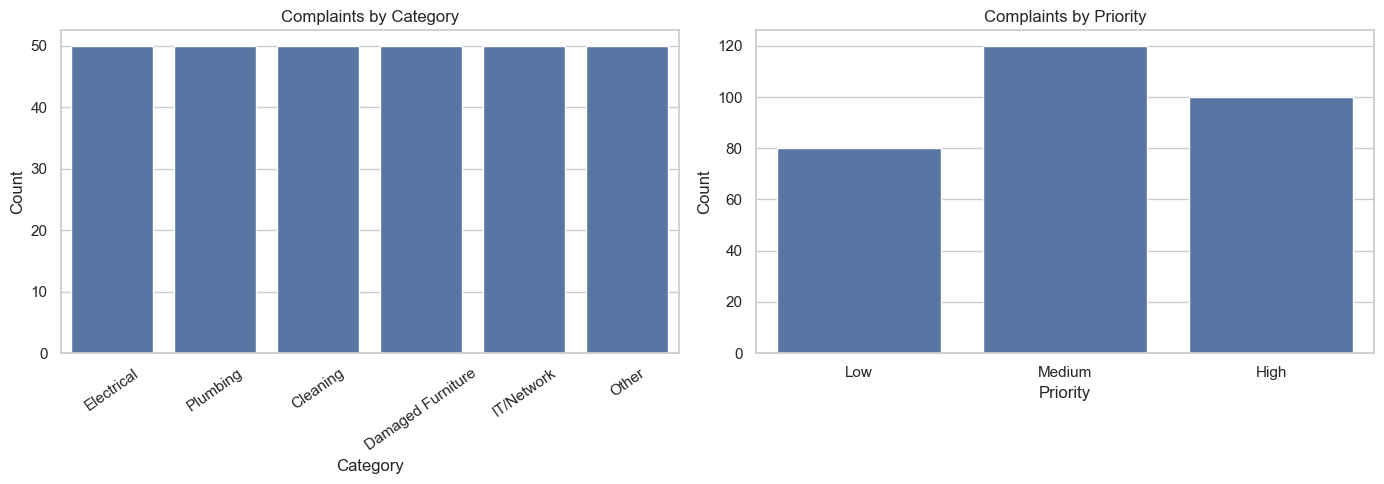

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df_v4,
    x="category",
    order=df_v4["category"].value_counts().index,
    ax=axes[0]
)
axes[0].set_title("Complaints by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=35)

sns.countplot(
    data=df_v4,
    x="priority",
    order=["Low", "Medium", "High"],
    ax=axes[1]
)
axes[1].set_title("Complaints by Priority")
axes[1].set_xlabel("Priority")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

priority,High,Low,Medium
category,,,
Cleaning,10,20,20
Damaged Furniture,15,15,20
Electrical,25,10,15
IT/Network,15,10,25
Other,20,15,15
Plumbing,15,10,25


<Figure size 1100x600 with 0 Axes>

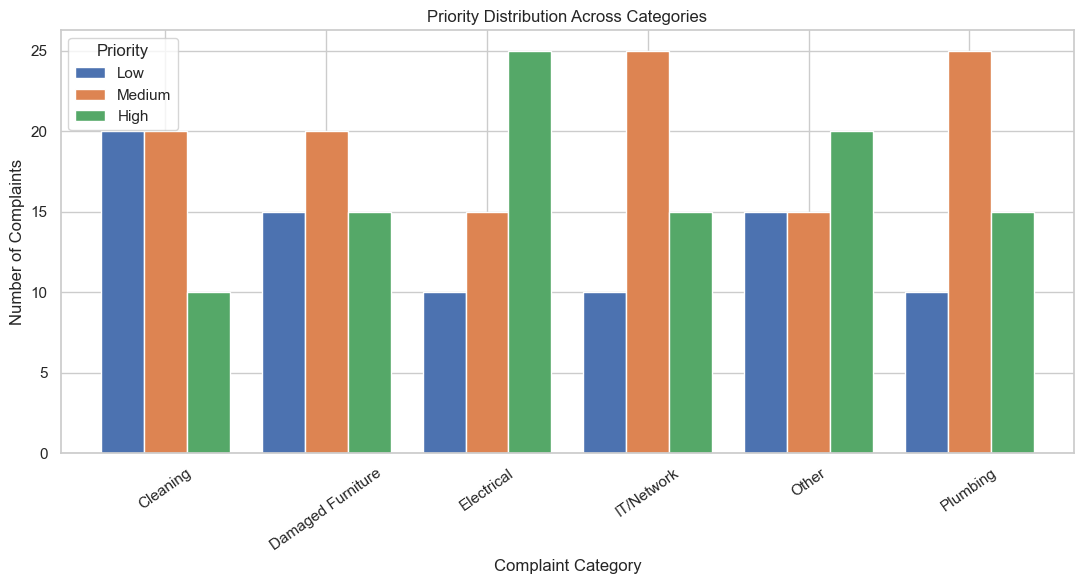

In [37]:
priority_category = pd.crosstab(
    df_v4["category"],
    df_v4["priority"]
)

display(priority_category)

plt.figure(figsize=(11, 6))

priority_category[["Low", "Medium", "High"]].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Priority Distribution Across Categories")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=35)
plt.legend(title="Priority")
plt.tight_layout()
plt.show()

In [38]:
# Create combined text feature
df_v4["text"] = (
    df_v4["title"].fillna("") + " " +
    df_v4["description"].fillna("")
).str.strip()

# Check the results
display(
    df_v4[["title", "description", "text", "category", "priority"]].head(10)
)

print("Total text records:", df_v4["text"].notna().sum())
print("Empty text records:", df_v4["text"].eq("").sum())
print("Unique text records:", df_v4["text"].nunique())

,title,description,text,category,priority
0,Ceiling Fan - Does not start when switched on (near the main entrance),"The campus helpdesk received this complaint: At Girls Hostel, the ceiling fan near the main entr...",Ceiling Fan - Does not start when switched on (near the main entrance) The campus helpdesk recei...,Electrical,Medium
1,Ceiling Fan - Does not start when switched on (on the ground floor),Ceiling fan on the ground floor at Main Gate does not start when switched on. The issue was noti...,Ceiling Fan - Does not start when switched on (on the ground floor) Ceiling fan on the ground fl...,Electrical,Medium
2,Ceiling Fan - Does not start when switched on (beside the student common area),Location: Sports Complex. Reported asset: ceiling fan. Observed condition: does not start when s...,Ceiling Fan - Does not start when switched on (beside the student common area) Location: Sports ...,Electrical,Medium
3,Ceiling Fan - Does not start when switched on (near the corridor junction),"A student submitted the complaint through the portal. The reported ceiling fan at Girls Hostel, ...",Ceiling Fan - Does not start when switched on (near the corridor junction) A student submitted t...,Electrical,Medium
4,Ceiling Fan - Does not start when switched on (inside the main facility),A student has reported the following problem: Ceiling fan does not start when switched on inside...,Ceiling Fan - Does not start when switched on (inside the main facility) A student has reported ...,Electrical,Medium
5,Tube Light - Flickers continuously during use (near the main entrance),"Kindly arrange a check for the following issue: At Girls Hostel, the tube light near the main en...",Tube Light - Flickers continuously during use (near the main entrance) Kindly arrange a check fo...,Electrical,Medium
6,Tube Light - Flickers continuously during use (on the ground floor),Tube light on the ground floor at Cafeteria flickers continuously during use. The issue was noti...,Tube Light - Flickers continuously during use (on the ground floor) Tube light on the ground flo...,Electrical,Medium
7,Tube Light - Flickers continuously during use (beside the student common area),Location: Academic Block B. Reported asset: tube light. Observed condition: flickers continuousl...,Tube Light - Flickers continuously during use (beside the student common area) Location: Academi...,Electrical,Medium
8,Tube Light - Flickers continuously during use (near the corridor junction),"A student submitted the complaint through the portal. The reported tube light at Cafeteria, near...",Tube Light - Flickers continuously during use (near the corridor junction) A student submitted t...,Electrical,Medium
9,Tube Light - Flickers continuously during use (inside the main facility),The campus helpdesk received this complaint: Tube light flickers continuously during use inside ...,Tube Light - Flickers continuously during use (inside the main facility) The campus helpdesk rec...,Electrical,Medium


Total text records: 300
Empty text records: 0
Unique text records: 300


In [39]:
from sklearn.model_selection import train_test_split

X = df_v4[["text", "location"]].copy()

y_category = df_v4["category"]
y_priority = df_v4["priority"]

X_train, X_test, y_category_train, y_category_test, y_priority_train, y_priority_test = train_test_split(
    X,
    y_category,
    y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining category distribution:")
print(y_category_train.value_counts())

print("\nTesting category distribution:")
print(y_category_test.value_counts())

print("\nTraining priority distribution:")
print(y_priority_train.value_counts())

print("\nTesting priority distribution:")
print(y_priority_test.value_counts())

Training records: 240
Testing records: 60

Training category distribution:
category
Other                40
Damaged Furniture    40
Electrical           40
IT/Network           40
Cleaning             40
Plumbing             40
Name: count, dtype: int64

Testing category distribution:
category
Electrical           10
Cleaning             10
Damaged Furniture    10
IT/Network           10
Plumbing             10
Other                10
Name: count, dtype: int64

Training priority distribution:
priority
Medium    95
High      79
Low       66
Name: count, dtype: int64

Testing priority distribution:
priority
Medium    25
High      21
Low       14
Name: count, dtype: int64


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer(
    transformers=[
        (
            "word_tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                max_features=5000,
                sublinear_tf=True
            ),
            "text"
        ),
        (
            "char_tfidf",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=(3, 5),
                max_features=5000,
                sublinear_tf=True
            ),
            "text"
        ),
        (
            "location",
            OneHotEncoder(handle_unknown="ignore"),
            ["location"]
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [41]:
# Category Classification Model

category_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            C=1.0
        ))
    ]
)

category_model.fit(X_train, y_category_train)

print("Category model trained successfully!")

Category model trained successfully!


In [42]:
# Priority Classification Model

priority_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            C=1.0
        ))
    ]
)

priority_model.fit(X_train, y_priority_train)

print("Priority model trained successfully!")

Priority model trained successfully!


CATEGORY MODEL EVALUATION
Accuracy: 1.0
Macro F1 Score: 1.0

Classification Report:
                   precision    recall  f1-score   support

         Cleaning       1.00      1.00      1.00        10
Damaged Furniture       1.00      1.00      1.00        10
       Electrical       1.00      1.00      1.00        10
       IT/Network       1.00      1.00      1.00        10
            Other       1.00      1.00      1.00        10
         Plumbing       1.00      1.00      1.00        10

         accuracy                           1.00        60
        macro avg       1.00      1.00      1.00        60
     weighted avg       1.00      1.00      1.00        60



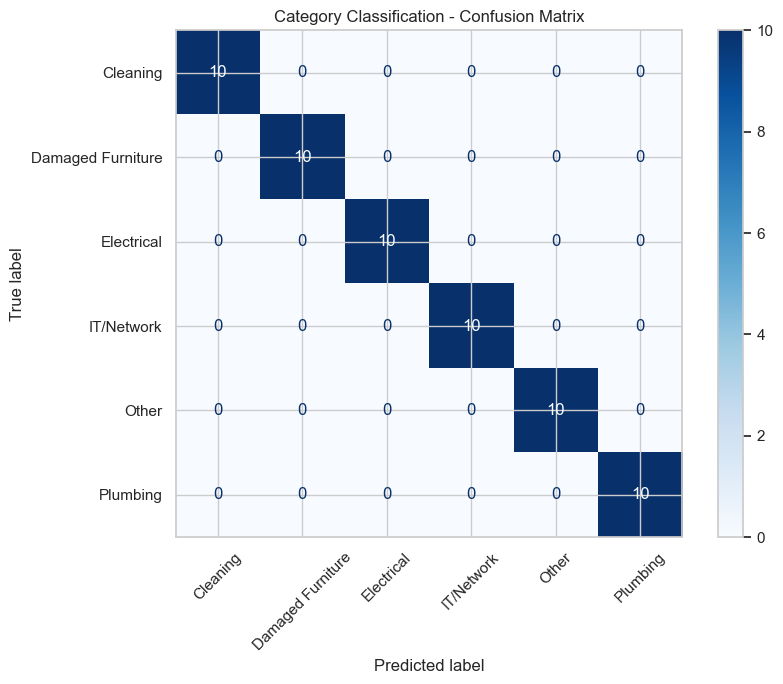

In [43]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Predict categories
y_category_pred = category_model.predict(X_test)

# Evaluation metrics
print("CATEGORY MODEL EVALUATION")
print("=" * 50)

print("Accuracy:", round(
    accuracy_score(y_category_test, y_category_pred), 4
))

print("Macro F1 Score:", round(
    f1_score(y_category_test, y_category_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_category_test,
    y_category_pred,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(
    y_category_test,
    y_category_pred,
    labels=category_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=category_model.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Category Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

PRIORITY MODEL EVALUATION
Accuracy: 1.0
Macro F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        21
         Low       1.00      1.00      1.00        14
      Medium       1.00      1.00      1.00        25

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



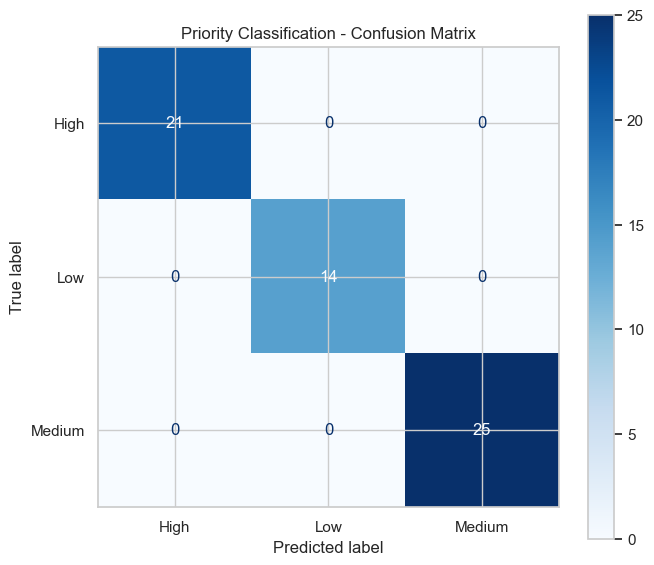

In [44]:
# Priority Model Evaluation

y_priority_pred = priority_model.predict(X_test)

print("PRIORITY MODEL EVALUATION")
print("=" * 50)

print("Accuracy:", round(
    accuracy_score(y_priority_test, y_priority_pred), 4
))

print("Macro F1 Score:", round(
    f1_score(y_priority_test, y_priority_pred, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_priority_test,
    y_priority_pred,
    zero_division=0
))

# Confusion Matrix
cm_priority = confusion_matrix(
    y_priority_test,
    y_priority_pred,
    labels=priority_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_priority,
    display_labels=priority_model.classes_
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues")
plt.title("Priority Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [45]:
unseen_complaints = pd.DataFrame({
    "text": [
        "Water is leaking continuously from the ceiling pipe and the floor has become slippery.",
        "Several computers in the laboratory cannot connect to the campus network.",
        "The classroom fan makes a loud noise but continues running.",
        "Broken glass from a window is lying near the student walking area.",
        "Dustbins in the cafeteria are full and waste is scattered around.",
        "The library printer is not printing documents.",
        "A chair has a loose screw and needs repair.",
        "There is a burning smell coming from the electrical control panel.",
        "The direction board near the main gate is faded and difficult to read.",
        "Water pressure in the hostel washroom is very low."
    ],
    "location": [
        "Academic Block A",
        "Computer Lab 3",
        "Library",
        "Main Gate",
        "Cafeteria",
        "Library",
        "Academic Block B",
        "Electrical Panel",
        "Main Gate",
        "Girls Hostel"
    ]
})

unseen_complaints["predicted_category"] = category_model.predict(
    unseen_complaints[["text", "location"]]
)

unseen_complaints["predicted_priority"] = priority_model.predict(
    unseen_complaints[["text", "location"]]
)

display(unseen_complaints)

,text,location,predicted_category,predicted_priority
0,Water is leaking continuously from the ceiling pipe and the floor has become slippery.,Academic Block A,Plumbing,Medium
1,Several computers in the laboratory cannot connect to the campus network.,Computer Lab 3,IT/Network,Medium
2,The classroom fan makes a loud noise but continues running.,Library,Electrical,Low
3,Broken glass from a window is lying near the student walking area.,Main Gate,Damaged Furniture,High
4,Dustbins in the cafeteria are full and waste is scattered around.,Cafeteria,Cleaning,Medium
5,The library printer is not printing documents.,Library,IT/Network,Low
6,A chair has a loose screw and needs repair.,Academic Block B,Damaged Furniture,Low
7,There is a burning smell coming from the electrical control panel.,Electrical Panel,Electrical,High
8,The direction board near the main gate is faded and difficult to read.,Main Gate,Other,Medium
9,Water pressure in the hostel washroom is very low.,Girls Hostel,Plumbing,Medium


In [46]:
# Expected labels based on our defined complaint classification rules

actual_category = [
    "Plumbing",
    "IT/Network",
    "Electrical",
    "Other",
    "Cleaning",
    "IT/Network",
    "Damaged Furniture",
    "Electrical",
    "Other",
    "Plumbing"
]

actual_priority = [
    "High",
    "Medium",
    "Medium",
    "High",
    "Medium",
    "Low",
    "Low",
    "High",
    "Low",
    "Medium"
]

print("MANUAL VALIDATION RESULTS")
print("=" * 50)

print("Category Accuracy:",
      accuracy_score(actual_category,
                     unseen_complaints["predicted_category"]))

print("Priority Accuracy:",
      accuracy_score(actual_priority,
                     unseen_complaints["predicted_priority"]))

print("\nCategory Classification Report:")
print(classification_report(
    actual_category,
    unseen_complaints["predicted_category"],
    zero_division=0
))

print("\nPriority Classification Report:")
print(classification_report(
    actual_priority,
    unseen_complaints["predicted_priority"],
    zero_division=0
))

MANUAL VALIDATION RESULTS
Category Accuracy: 0.9
Priority Accuracy: 0.7

Category Classification Report:
                   precision    recall  f1-score   support

         Cleaning       1.00      1.00      1.00         1
Damaged Furniture       0.50      1.00      0.67         1
       Electrical       1.00      1.00      1.00         2
       IT/Network       1.00      1.00      1.00         2
            Other       1.00      0.50      0.67         2
         Plumbing       1.00      1.00      1.00         2

         accuracy                           0.90        10
        macro avg       0.92      0.92      0.89        10
     weighted avg       0.95      0.90      0.90        10


Priority Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.67      0.80         3
         Low       0.67      0.67      0.67         3
      Medium       0.60      0.75      0.67         4

    accuracy                           0.70        

In [47]:
# Priority prediction probabilities

priority_probabilities = priority_model.predict_proba(
    unseen_complaints[["text", "location"]]
)

probability_df = pd.DataFrame(
    priority_probabilities,
    columns=priority_model.classes_
)

probability_df.insert(
    0, "Complaint",
    unseen_complaints["text"].str[:55]
)

probability_df["Predicted Priority"] = (
    unseen_complaints["predicted_priority"].values
)

display(probability_df.round(3))

,Complaint,High,Low,Medium,Predicted Priority
0,Water is leaking continuously from the ceiling pipe and,0.412,0.135,0.453,Medium
1,Several computers in the laboratory cannot connect to t,0.356,0.099,0.545,Medium
2,The classroom fan makes a loud noise but continues runn,0.187,0.690,0.123,Low
3,Broken glass from a window is lying near the student wa,0.469,0.110,0.421,High
4,Dustbins in the cafeteria are full and waste is scatter,0.247,0.137,0.616,Medium
5,The library printer is not printing documents.,0.310,0.411,0.279,Low
6,A chair has a loose screw and needs repair.,0.103,0.658,0.239,Low
7,There is a burning smell coming from the electrical con,0.733,0.111,0.156,High
8,The direction board near the main gate is faded and dif,0.267,0.294,0.439,Medium
9,Water pressure in the hostel washroom is very low.,0.185,0.099,0.716,Medium


In [48]:
# Calculate confidence and prediction margin

priority_probabilities = priority_model.predict_proba(
    unseen_complaints[["text", "location"]]
)

sorted_probs = np.sort(priority_probabilities, axis=1)

unseen_complaints["confidence"] = sorted_probs[:, -1]
unseen_complaints["margin"] = (
    sorted_probs[:, -1] - sorted_probs[:, -2]
)

# Diagnostic review flag
unseen_complaints["review_required"] = (
    (unseen_complaints["confidence"] < 0.60) |
    (unseen_complaints["margin"] < 0.15)
)

display(
    unseen_complaints[
        ["text", "predicted_priority",
         "confidence", "margin", "review_required"]
    ].round(3)
)

,text,predicted_priority,confidence,margin,review_required
0,Water is leaking continuously from the ceiling pipe and the floor has become slippery.,Medium,0.453,0.041,True
1,Several computers in the laboratory cannot connect to the campus network.,Medium,0.545,0.190,True
2,The classroom fan makes a loud noise but continues running.,Low,0.690,0.503,False
3,Broken glass from a window is lying near the student walking area.,High,0.469,0.048,True
4,Dustbins in the cafeteria are full and waste is scattered around.,Medium,0.616,0.369,False
5,The library printer is not printing documents.,Low,0.411,0.101,True
6,A chair has a loose screw and needs repair.,Low,0.658,0.419,False
7,There is a burning smell coming from the electrical control panel.,High,0.733,0.577,False
8,The direction board near the main gate is faded and difficult to read.,Medium,0.439,0.145,True
9,Water pressure in the hostel washroom is very low.,Medium,0.716,0.531,False


In [49]:
def safety_priority_check(text):
    text = text.lower()

    high_risk_keywords = [
        "burning smell",
        "exposed wire",
        "electric shock",
        "sparking",
        "burst pipe",
        "slippery floor",
        "broken glass",
        "sharp edge",
        "loose railing",
        "trip hazard"
    ]

    if any(keyword in text for keyword in high_risk_keywords):
        return "High"

    return None


unseen_complaints["safety_priority"] = (
    unseen_complaints["text"].apply(safety_priority_check)
)

display(
    unseen_complaints[
        ["text", "predicted_priority", "safety_priority"]
    ]
)

,text,predicted_priority,safety_priority
0,Water is leaking continuously from the ceiling pipe and the floor has become slippery.,Medium,None
1,Several computers in the laboratory cannot connect to the campus network.,Medium,None
2,The classroom fan makes a loud noise but continues running.,Low,None
3,Broken glass from a window is lying near the student walking area.,High,High
4,Dustbins in the cafeteria are full and waste is scattered around.,Medium,None
5,The library printer is not printing documents.,Low,None
6,A chair has a loose screw and needs repair.,Low,None
7,There is a burning smell coming from the electrical control panel.,High,High
8,The direction board near the main gate is faded and difficult to read.,Medium,None
9,Water pressure in the hostel washroom is very low.,Medium,None


In [50]:
def safety_priority_check(text):
    text = text.lower()

    high_risk_keywords = [
        "burning smell",
        "exposed wire",
        "electric shock",
        "sparking",
        "burst pipe",
        "slippery floor",
        "water leakage",
        "water leaking",
        "broken glass",
        "sharp edge",
        "loose railing",
        "trip hazard",
        "fire",
        "smoke",
        "ceiling collapse"
    ]

    if any(keyword in text for keyword in high_risk_keywords):
        return "High"

    return None


unseen_complaints["safety_priority"] = (
    unseen_complaints["text"].apply(safety_priority_check)
)

display(
    unseen_complaints[
        ["text", "predicted_priority", "safety_priority"]
    ]
)

,text,predicted_priority,safety_priority
0,Water is leaking continuously from the ceiling pipe and the floor has become slippery.,Medium,None
1,Several computers in the laboratory cannot connect to the campus network.,Medium,None
2,The classroom fan makes a loud noise but continues running.,Low,None
3,Broken glass from a window is lying near the student walking area.,High,High
4,Dustbins in the cafeteria are full and waste is scattered around.,Medium,None
5,The library printer is not printing documents.,Low,None
6,A chair has a loose screw and needs repair.,Low,None
7,There is a burning smell coming from the electrical control panel.,High,High
8,The direction board near the main gate is faded and difficult to read.,Medium,None
9,Water pressure in the hostel washroom is very low.,Medium,None


In [51]:
def safety_priority_check(text):
    text = text.lower()

    high_risk_keywords = [
        "burning smell",
        "exposed wire",
        "electric shock",
        "sparking",
        "burst pipe",
        "slippery floor",
        "water leakage",
        "water leaking",
        "water is leaking",
        "floor has become slippery",
        "broken glass",
        "sharp edge",
        "loose railing",
        "trip hazard",
        "fire",
        "smoke",
        "ceiling collapse"
    ]

    if any(keyword in text for keyword in high_risk_keywords):
        return "High"

    return None


unseen_complaints["safety_priority"] = (
    unseen_complaints["text"].apply(safety_priority_check)
)

display(
    unseen_complaints[
        ["text", "predicted_priority", "safety_priority"]
    ]
)

,text,predicted_priority,safety_priority
0,Water is leaking continuously from the ceiling pipe and the floor has become slippery.,Medium,High
1,Several computers in the laboratory cannot connect to the campus network.,Medium,None
2,The classroom fan makes a loud noise but continues running.,Low,None
3,Broken glass from a window is lying near the student walking area.,High,High
4,Dustbins in the cafeteria are full and waste is scattered around.,Medium,None
5,The library printer is not printing documents.,Low,None
6,A chair has a loose screw and needs repair.,Low,None
7,There is a burning smell coming from the electrical control panel.,High,High
8,The direction board near the main gate is faded and difficult to read.,Medium,None
9,Water pressure in the hostel washroom is very low.,Medium,None


In [52]:
def final_priority_decision(row):
    if row["safety_priority"] == "High":
        return "High", "Safety Rule Override"

    if row["review_required"]:
        return row["predicted_priority"], "Manual Review Required"

    return row["predicted_priority"], "ML Prediction"


decisions = unseen_complaints.apply(
    final_priority_decision,
    axis=1
)

unseen_complaints["final_priority"] = [
    decision[0] for decision in decisions
]

unseen_complaints["decision_status"] = [
    decision[1] for decision in decisions
]

display(
    unseen_complaints[
        [
            "text",
            "predicted_priority",
            "final_priority",
            "decision_status"
        ]
    ]
)

,text,predicted_priority,final_priority,decision_status
0,Water is leaking continuously from the ceiling pipe and the floor has become slippery.,Medium,High,Safety Rule Override
1,Several computers in the laboratory cannot connect to the campus network.,Medium,Medium,Manual Review Required
2,The classroom fan makes a loud noise but continues running.,Low,Low,ML Prediction
3,Broken glass from a window is lying near the student walking area.,High,High,Safety Rule Override
4,Dustbins in the cafeteria are full and waste is scattered around.,Medium,Medium,ML Prediction
5,The library printer is not printing documents.,Low,Low,Manual Review Required
6,A chair has a loose screw and needs repair.,Low,Low,ML Prediction
7,There is a burning smell coming from the electrical control panel.,High,High,Safety Rule Override
8,The direction board near the main gate is faded and difficult to read.,Medium,Medium,Manual Review Required
9,Water pressure in the hostel washroom is very low.,Medium,Medium,ML Prediction


In [53]:
import os
import joblib

# Create model directory
os.makedirs("models", exist_ok=True)

# Save both models and metadata
model_bundle_v4 = {
    "category_model": category_model,
    "priority_model": priority_model,
    "version": "v4",
    "features": ["text", "location"],
    "category_classes": list(category_model.classes_),
    "priority_classes": list(priority_model.classes_),
    "review_confidence_threshold": 0.60,
    "review_margin_threshold": 0.15
}

model_path = "models/campus_maintenance_models_v4.joblib"

joblib.dump(model_bundle_v4, model_path)

print("Models saved successfully!")
print("Location:", model_path)
print("File exists:", os.path.exists(model_path))

Models saved successfully!
Location: models/campus_maintenance_models_v4.joblib
File exists: True


In [54]:
try:
    import xgboost as xgb
    print("XGBoost installed:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

from sklearn.ensemble import RandomForestClassifier

print("Random Forest is ready!")

XGBoost installed: 3.4.1
Random Forest is ready!


In [55]:
from sklearn.ensemble import RandomForestClassifier

rf_category_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            min_samples_split=4,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_category_model.fit(X_train, y_category_train)

print("Random Forest Category Model trained successfully!")

Random Forest Category Model trained successfully!


In [56]:
rf_priority_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            min_samples_split=4,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_priority_model.fit(X_train, y_priority_train)

print("Random Forest Priority Model trained successfully!")

Random Forest Priority Model trained successfully!


In [57]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Encode category labels
category_encoder = LabelEncoder()

y_category_train_encoded = category_encoder.fit_transform(
    y_category_train
)

xgb_category_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=len(category_encoder.classes_),
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_category_model.fit(
    X_train,
    y_category_train_encoded
)

print("XGBoost Category Model trained successfully!")

XGBoost Category Model trained successfully!


In [58]:
# Encode priority labels
priority_encoder = LabelEncoder()

y_priority_train_encoded = priority_encoder.fit_transform(
    y_priority_train
)

# XGBoost Priority Model
xgb_priority_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="multi:softprob",
            num_class=len(priority_encoder.classes_),
            eval_metric="mlogloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_priority_model.fit(
    X_train,
    y_priority_train_encoded
)

print("XGBoost Priority Model trained successfully!")

XGBoost Priority Model trained successfully!


In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []

# All trained models
models = {
    "Logistic Regression": (category_model, priority_model),
    "Random Forest": (rf_category_model, rf_priority_model)
}

# Category predictions
for model_name, (cat_model, pri_model) in models.items():

    cat_pred = cat_model.predict(X_test)
    pri_pred = pri_model.predict(X_test)

    results.append({
        "Algorithm": model_name,
        "Task": "Category",
        "Accuracy": accuracy_score(y_category_test, cat_pred),
        "Precision": precision_score(
            y_category_test, cat_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_category_test, cat_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_category_test, cat_pred, average="macro", zero_division=0
        )
    })

    results.append({
        "Algorithm": model_name,
        "Task": "Priority",
        "Accuracy": accuracy_score(y_priority_test, pri_pred),
        "Precision": precision_score(
            y_priority_test, pri_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_priority_test, pri_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_priority_test, pri_pred, average="macro", zero_division=0
        )
    })


# XGBoost Category predictions
xgb_cat_encoded = xgb_category_model.predict(X_test).astype(int)
xgb_cat_pred = category_encoder.inverse_transform(xgb_cat_encoded)

# XGBoost Priority predictions
xgb_pri_encoded = xgb_priority_model.predict(X_test).astype(int)
xgb_pri_pred = priority_encoder.inverse_transform(xgb_pri_encoded)

for task, actual, predicted in [
    ("Category", y_category_test, xgb_cat_pred),
    ("Priority", y_priority_test, xgb_pri_pred)
]:
    results.append({
        "Algorithm": "XGBoost",
        "Task": task,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            actual, predicted, average="macro", zero_division=0
        )
    })


comparison_df = pd.DataFrame(results)

display(
    comparison_df.round(4).sort_values(
        ["Task", "Macro F1"],
        ascending=[True, False]
    )
)

,Algorithm,Task,Accuracy,Precision,Recall,Macro F1
0,Logistic Regression,Category,1.0000,1.0000,1.0000,1.0000
2,Random Forest,Category,0.9667,0.9682,0.9667,0.9666
4,XGBoost,Category,0.9500,0.9515,0.9500,0.9500
1,Logistic Regression,Priority,1.0000,1.0000,1.0000,1.0000
3,Random Forest,Priority,0.9667,0.9753,0.9683,0.9705
5,XGBoost,Priority,0.9500,0.9643,0.9444,0.9521


In [60]:
# Compare all algorithms on 10 unseen complaints

manual_results = []

# Logistic Regression
manual_results.append({
    "Algorithm": "Logistic Regression",
    "Category Accuracy": accuracy_score(
        actual_category,
        category_model.predict(unseen_complaints[["text", "location"]])
    ),
    "Priority Accuracy": accuracy_score(
        actual_priority,
        priority_model.predict(unseen_complaints[["text", "location"]])
    )
})

# Random Forest
manual_results.append({
    "Algorithm": "Random Forest",
    "Category Accuracy": accuracy_score(
        actual_category,
        rf_category_model.predict(unseen_complaints[["text", "location"]])
    ),
    "Priority Accuracy": accuracy_score(
        actual_priority,
        rf_priority_model.predict(unseen_complaints[["text", "location"]])
    )
})

# XGBoost
xgb_cat_manual = category_encoder.inverse_transform(
    xgb_category_model.predict(
        unseen_complaints[["text", "location"]]
    ).astype(int)
)

xgb_pri_manual = priority_encoder.inverse_transform(
    xgb_priority_model.predict(
        unseen_complaints[["text", "location"]]
    ).astype(int)
)

manual_results.append({
    "Algorithm": "XGBoost",
    "Category Accuracy": accuracy_score(
        actual_category, xgb_cat_manual
    ),
    "Priority Accuracy": accuracy_score(
        actual_priority, xgb_pri_manual
    )
})

manual_comparison = pd.DataFrame(manual_results)

display(manual_comparison.round(3))

,Algorithm,Category Accuracy,Priority Accuracy
0,Logistic Regression,0.9,0.7
1,Random Forest,0.8,0.6
2,XGBoost,0.7,0.4


In [61]:
import joblib
import os

os.makedirs("models", exist_ok=True)

comparison_bundle = {
    "version": "v4",
    "selected_algorithm": "Logistic Regression",

    "category_models": {
        "Logistic Regression": category_model,
        "Random Forest": rf_category_model,
        "XGBoost": xgb_category_model
    },

    "priority_models": {
        "Logistic Regression": priority_model,
        "Random Forest": rf_priority_model,
        "XGBoost": xgb_priority_model
    },

    "category_encoder": category_encoder,
    "priority_encoder": priority_encoder,

    "preprocessing": preprocessor,

    "review_confidence_threshold": 0.60,
    "review_margin_threshold": 0.15
}

joblib.dump(
    comparison_bundle,
    "models/campus_maintenance_comparison_v4.joblib"
)

print("All three algorithms saved successfully!")
print("File exists:",
      os.path.exists("models/campus_maintenance_comparison_v4.joblib"))

All three algorithms saved successfully!
File exists: True
